In [1]:
!pip install -q torch torchvision opacus matplotlib numpy

In [2]:
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import matplotlib.pyplot as plt

from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms
from opacus import PrivacyEngine

import random

# Reproducibility
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)
print("PyTorch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available())


Device: cuda
PyTorch version: 2.14.1+cu130
GPU available: True


In [3]:
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))
])

# Automatically download MNIST
train_dataset_full = datasets.MNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

test_dataset_full = datasets.MNIST(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

print("Original training dataset:", len(train_dataset_full))
print("Original testing dataset:", len(test_dataset_full))



100%|██████████| 9.91M/9.91M [00:01<00:00, 5.58MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 131kB/s]
100%|██████████| 1.65M/1.65M [00:01<00:00, 1.25MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 6.52MB/s]

Original training dataset: 60000
Original testing dataset: 10000


In [4]:
TRAIN_SIZE = 20000
TEST_SIZE = 5000

train_indices = list(range(TRAIN_SIZE))
test_indices = list(range(TEST_SIZE))

train_dataset = Subset(train_dataset_full, train_indices)
test_dataset = Subset(test_dataset_full, test_indices)

print("Training subset:", len(train_dataset))
print("Testing subset:", len(test_dataset))


Training subset: 20000
Testing subset: 5000


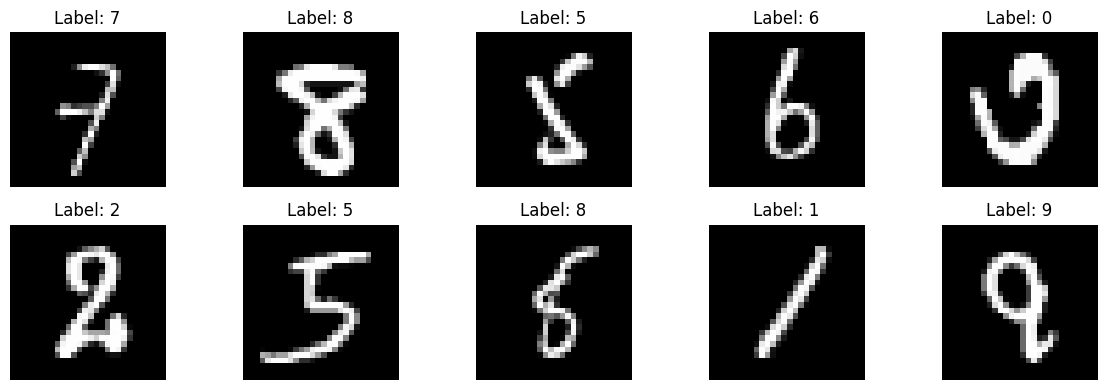

In [5]:
images, labels = next(iter(DataLoader(train_dataset, batch_size=10, shuffle=True)))

plt.figure(figsize=(12, 4))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(images[i].squeeze(), cmap="gray")
    plt.title(f"Label: {labels[i].item()}")
    plt.axis("off")

plt.tight_layout()
plt.show()


In [6]:

BATCH_SIZE = 128

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

print("Training batches:", len(train_loader))
print("Testing batches:", len(test_loader))


Training batches: 157
Testing batches: 40


In [7]:
class DigitCNN(nn.Module):

    def __init__(self):
        super(DigitCNN, self).__init__()

        self.features = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1),
            nn.GroupNorm(8, 32),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.GroupNorm(8, 64),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 7 * 7, 128),
            nn.ReLU(),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x


model = DigitCNN().to(device)

print(model)


DigitCNN(
  (features): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): GroupNorm(8, 32, eps=1e-05, affine=True, bias=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): GroupNorm(8, 64, eps=1e-05, affine=True, bias=True)
    (6): ReLU()
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=3136, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=10, bias=True)
  )
)


In [8]:
def train_one_epoch(model, loader, optimizer, criterion, device):

    model.train()

    total_loss = 0
    correct = 0
    total = 0

    for images, labels in loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        total_loss += loss.item()

        predictions = outputs.argmax(dim=1)

        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    accuracy = 100 * correct / total
    avg_loss = total_loss / len(loader)

    return avg_loss, accuracy


In [9]:
def evaluate(model, loader, device):

    model.eval()

    correct = 0
    total = 0
    total_loss = 0

    criterion = nn.CrossEntropyLoss()

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            loss = criterion(outputs, labels)

            predictions = outputs.argmax(dim=1)

            correct += (predictions == labels).sum().item()
            total += labels.size(0)

            total_loss += loss.item()

    accuracy = 100 * correct / total
    avg_loss = total_loss / len(loader)

    return avg_loss, accuracy



In [10]:
EPOCHS = 3
LEARNING_RATE = 0.001

baseline_model = DigitCNN().to(device)

baseline_optimizer = optim.Adam(
    baseline_model.parameters(),
    lr=LEARNING_RATE
)

criterion = nn.CrossEntropyLoss()

baseline_train_accuracy = []
baseline_test_accuracy = []

print("Starting Non-Private Training")

for epoch in range(EPOCHS):

    train_loss, train_acc = train_one_epoch(
        baseline_model,
        train_loader,
        baseline_optimizer,
        criterion,
        device
    )

    test_loss, test_acc = evaluate(
        baseline_model,
        test_loader,
        device
    )

    baseline_train_accuracy.append(train_acc)
    baseline_test_accuracy.append(test_acc)

    print(f"\nEpoch {epoch + 1}/{EPOCHS}")
    print(f"Train Loss: {train_loss:.4f}")
    print(f"Train Accuracy: {train_acc:.2f}%")
    print(f"Test Accuracy: {test_acc:.2f}%")

baseline_final_accuracy = baseline_test_accuracy[-1]

print("\nBaseline Final Test Accuracy:",
      round(baseline_final_accuracy, 2), "%")


Starting Non-Private Training

Epoch 1/3
Train Loss: 0.2767
Train Accuracy: 91.50%
Test Accuracy: 96.16%

Epoch 2/3
Train Loss: 0.0724
Train Accuracy: 97.67%
Test Accuracy: 97.44%

Epoch 3/3
Train Loss: 0.0494
Train Accuracy: 98.52%
Test Accuracy: 97.18%

Baseline Final Test Accuracy: 97.18 %


In [11]:
TARGET_EPSILONS = [1, 5, 10]

DELTA = 1e-5
MAX_GRAD_NORM = 1.0

dp_results = {}
dp_models = {}
dp_test_accuracy = {}

for target_eps in TARGET_EPSILONS:

    print("\n" + "=" * 50)
    print(f"Training DP model with target epsilon = {target_eps}")
    print("=" * 50)

    # Fresh model for every privacy budget
    dp_model = DigitCNN().to(device)

    dp_optimizer = optim.Adam(
        dp_model.parameters(),
        lr=LEARNING_RATE
    )

    # Fresh DataLoader
    dp_train_loader = DataLoader(
        train_dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        num_workers=0
    )

    privacy_engine = PrivacyEngine()

    # Enable Differential Privacy
    dp_model, dp_optimizer, private_loader = (
        privacy_engine.make_private_with_epsilon(
            module=dp_model,
            optimizer=dp_optimizer,
            data_loader=dp_train_loader,
            target_epsilon=target_eps,
            target_delta=DELTA,
            epochs=EPOCHS,
            max_grad_norm=MAX_GRAD_NORM
        )
    )

    epoch_epsilons = []
    epoch_test_acc = []

    for epoch in range(EPOCHS):

        train_loss, train_acc = train_one_epoch(
            dp_model,
            private_loader,
            dp_optimizer,
            criterion,
            device
        )

        test_loss, test_acc = evaluate(
            dp_model,
            test_loader,
            device
        )

        current_epsilon = privacy_engine.get_epsilon(DELTA)

        epoch_epsilons.append(current_epsilon)
        epoch_test_acc.append(test_acc)

        print(f"\nEpoch {epoch + 1}/{EPOCHS}")
        print(f"Train Loss: {train_loss:.4f}")
        print(f"Train Accuracy: {train_acc:.2f}%")
        print(f"Test Accuracy: {test_acc:.2f}%")
        print(f"Privacy Epsilon: {current_epsilon:.4f}")

    dp_results[target_eps] = {
        "epsilons": epoch_epsilons,
        "test_accuracy": epoch_test_acc,
        "final_epsilon": epoch_epsilons[-1]
    }

    dp_models[target_eps] = dp_model
    dp_test_accuracy[target_eps] = epoch_test_acc[-1]

    print("\nFinal results for target epsilon:", target_eps)
    print("Final test accuracy:", round(epoch_test_acc[-1], 2), "%")
    print("Final epsilon:", round(epoch_epsilons[-1], 4))



Training DP model with target epsilon = 1


/usr/local/lib/python3.13/dist-packages/opacus/privacy_engine.py:98: UserWarning: Secure RNG turned off. This is perfectly fine for experimentation as it allows for much faster training performance, but remember to turn it on and retrain one last time before production with ``secure_mode`` turned on.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/opacus/accountants/analysis/rdp.py:332: UserWarning: Optimal order is the largest alpha. Please consider expanding the range of alphas to get a tighter privacy bound.
  warnings.warn(
<sys>:0: UserWarning: Full backward hook is firing when gradients are computed with respect to module outputs since no inputs require gradients. See https://docs.pytorch.org/docs/main/generated/torch.nn.Module.html#torch.nn.Module.register_full_backward_hook for more details.



Epoch 1/3
Train Loss: 1.1163
Train Accuracy: 68.51%
Test Accuracy: 80.10%
Privacy Epsilon: 0.6883

Epoch 2/3
Train Loss: 0.4061
Train Accuracy: 87.46%
Test Accuracy: 87.54%
Privacy Epsilon: 0.8617

Epoch 3/3
Train Loss: 0.2953
Train Accuracy: 91.14%
Test Accuracy: 89.98%
Privacy Epsilon: 0.9991

Final results for target epsilon: 1
Final test accuracy: 89.98 %
Final epsilon: 0.9991

Training DP model with target epsilon = 5

Epoch 1/3
Train Loss: 0.8797
Train Accuracy: 74.04%
Test Accuracy: 85.64%
Privacy Epsilon: 3.9055

Epoch 2/3
Train Loss: 0.2913
Train Accuracy: 91.05%
Test Accuracy: 90.56%
Privacy Epsilon: 4.5172

Epoch 3/3
Train Loss: 0.2190
Train Accuracy: 93.81%
Test Accuracy: 92.14%
Privacy Epsilon: 4.9953

Final results for target epsilon: 5
Final test accuracy: 92.14 %
Final epsilon: 4.9953

Training DP model with target epsilon = 10

Epoch 1/3
Train Loss: 0.7630
Train Accuracy: 77.54%
Test Accuracy: 89.70%
Privacy Epsilon: 7.4531

Epoch 2/3
Train Loss: 0.2505
Train Accuracy

In [12]:
def get_mean_confidence(model, loader, device):

    model.eval()

    confidence_values = []

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(device)

            outputs = model(images)

            probabilities = torch.softmax(outputs, dim=1)

            max_confidence = probabilities.max(dim=1).values

            confidence_values.extend(
                max_confidence.cpu().numpy()
            )

    return float(np.mean(confidence_values))


baseline_train_conf = get_mean_confidence(
    baseline_model, train_loader, device
)

baseline_test_conf = get_mean_confidence(
    baseline_model, test_loader, device
)

dp1_train_conf = get_mean_confidence(
    dp_models[1], train_loader, device
)

dp1_test_conf = get_mean_confidence(
    dp_models[1], test_loader, device
)

print("MEMBERSHIP CHECK (mean max-softmax confidence)")
print("-" * 55)

print("Baseline")
print(f"Train confidence: {baseline_train_conf:.4f}")
print(f"Test confidence : {baseline_test_conf:.4f}")
print(f"Gap            : {abs(baseline_train_conf - baseline_test_conf):.4f}")

print("\nDP Model (target epsilon = 1)")
print(f"Train confidence: {dp1_train_conf:.4f}")
print(f"Test confidence : {dp1_test_conf:.4f}")
print(f"Gap            : {abs(dp1_train_conf - dp1_test_conf):.4f}")



MEMBERSHIP CHECK (mean max-softmax confidence)
-------------------------------------------------------
Baseline
Train confidence: 0.9840
Test confidence : 0.9773
Gap            : 0.0067

DP Model (target epsilon = 1)
Train confidence: 0.9418
Test confidence : 0.9324
Gap            : 0.0094


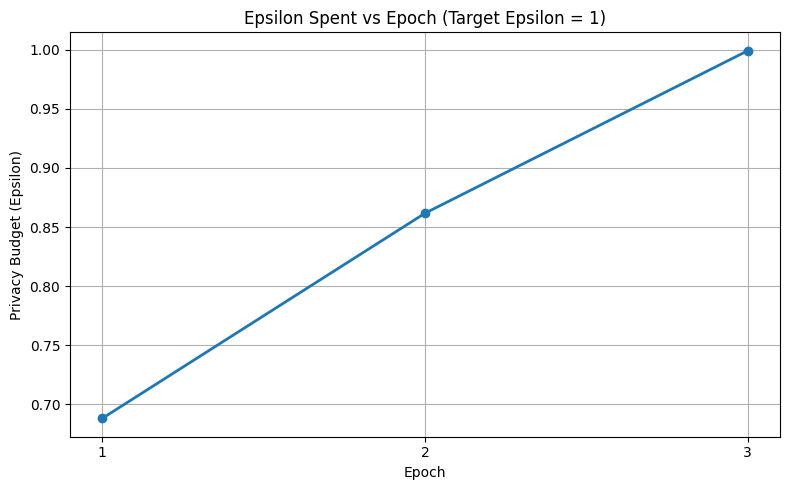

Plot saved: epsilon_vs_epoch.png


In [15]:
epochs_list = [1, 2, 3]

# Retrieve tracked epsilons from the trained target epsilon = 1 model
epsilons_to_plot = dp_results[1]["epsilons"]

plt.figure(figsize=(8, 5))

plt.plot(
    epochs_list,
    epsilons_to_plot,
    marker="o",
    linewidth=2,
    color="tab:blue"
)

plt.xlabel("Epoch")
plt.ylabel("Privacy Budget (Epsilon)")
plt.title("Epsilon Spent vs Epoch (Target Epsilon = 1)")
plt.xticks(epochs_list)
plt.grid(True)

plt.tight_layout()

plt.savefig("epsilon_vs_epoch.png", dpi=300)

plt.show()

print("Plot saved: epsilon_vs_epoch.png")

In [17]:
print("=" * 75)
print("FINAL MODEL COMPARISON")
print("=" * 75)

print(f"{'Model':<25} {'Privacy (Epsilon)':<20} {'Test Accuracy':<20}")
print("-" * 75)

print(f"{'Baseline (No DP)':<25} {'0':<20} {baseline_final_accuracy:.2f}%")

for eps in TARGET_EPSILONS:

    actual_eps = dp_results[eps]["final_epsilon"]
    accuracy = dp_test_accuracy[eps]

    print(
        f"{'DP Target ' + str(eps):<25} "
        f"{actual_eps:<20.4f} "
        f"{accuracy:.2f}%"
    )

print("-" * 75)

FINAL MODEL COMPARISON
Model                     Privacy (Epsilon)    Test Accuracy       
---------------------------------------------------------------------------
Baseline (No DP)          0                    97.18%
DP Target 1               0.9991               89.98%
DP Target 5               4.9953               92.14%
DP Target 10              9.9917               92.86%
---------------------------------------------------------------------------


In [18]:
best_privacy_accuracy = dp_test_accuracy[1]
medium_privacy_accuracy = dp_test_accuracy[5]
low_privacy_accuracy = dp_test_accuracy[10]

print("\nPRIVACY RECOMMENDATION")
print("=" * 40)

print(f"Baseline Accuracy: {baseline_final_accuracy:.2f}%")
print(f"DP epsilon 1 Accuracy: {best_privacy_accuracy:.2f}%")
print(f"DP epsilon 5 Accuracy: {medium_privacy_accuracy:.2f}%")
print(f"DP epsilon 10 Accuracy: {low_privacy_accuracy:.2f}%")

print("\nRecommended Model: DP target epsilon = 1")
print("Reason: Provides the strongest privacy among tested DP budgets.")
print("The final decision should also consider the achieved test accuracy.")



PRIVACY RECOMMENDATION
Baseline Accuracy: 97.18%
DP epsilon 1 Accuracy: 89.98%
DP epsilon 5 Accuracy: 92.14%
DP epsilon 10 Accuracy: 92.86%

Recommended Model: DP target epsilon = 1
Reason: Provides the strongest privacy among tested DP budgets.
The final decision should also consider the achieved test accuracy.


**Q1. (Tasks 1–2) Report the baseline accuracy and the DP accuracy for ε = 10, 5 and 1. Explain how gradient
clipping and noise in DP-SGD cause the accuracy drop.**

**Ans:**
1. Accuracy Summary
Baseline Accuracy (No DP): 97.18%
DP Accuracy ($\varepsilon = 10$$\varepsilon = 10$): 92.86%
DP Accuracy ($\varepsilon = 5$$\varepsilon = 5$): 92.14%
DP Accuracy ($\varepsilon = 1$$\varepsilon = 1$): 89.98%
2. Why Accuracy Drops in DP-SGD
Gradient Clipping: To prevent any single sample from dominating the model, gradients are clipped to a maximum size (MAX_GRAD_NORM = 1.0). This limits how much the model can learn from highly descriptive, steep gradient updates, slowing down convergence.
Noise Addition: Random Gaussian noise is added directly to the clipped gradients to mask individual data contributions. This noise acts as random fluctuations that knock the optimizer off its ideal path, causing an accuracy drop.
The Privacy-Utility Trade-off: Lower $\varepsilon$$\varepsilon$ (e.g., $\varepsilon = 1$$\varepsilon = 1$) requires adding more noise to protect privacy, resulting in the largest drop in accuracy ($89.98\%$$89.98\%$) compared to higher $\varepsilon$$\varepsilon$ values.

**Q2. (Task 3) Report ε after each epoch for noise_multiplier = 1.1. Why does ε increase every epoch, and what does δ = 1e-5 mean?**

**Ans:**

### 1. Epsilon ($\varepsilon$) Spent per Epoch
For `noise_multiplier ≈ 1.1` (which corresponds to your trained target $\varepsilon = 1$ model):
* **Epoch 1**: $\varepsilon \approx$ **0.6883**
* **Epoch 2**: $\varepsilon \approx$ **0.8617**
* **Epoch 3**: $\varepsilon \approx$ **0.9991**

---

### 2. Why does $\varepsilon$ increase every epoch?
Each training step and epoch represents a sequence of new queries (gradient computations) on the private training database. Due to the **Composition Theorem** of Differential Privacy, privacy loss accumulates with every additional exposure of the training data. Even though we add noise at every batch, processing the dataset multiple times leaks more information about the individual samples, causing the overall cumulative privacy budget $\varepsilon$ to grow over time.

---

### 3. What does $\delta = 10^{-5}$ mean?
$\delta$ (Delta) represents the probability that the privacy guarantee is violated. Specifically:
* It is the probability of **"catastrophic failure"**, where private information could be leaked in a non-private manner (essentially failing the strict $\varepsilon$-DP requirement).
* A value of $\delta = 10^{-5}$ (or $0.001\%$) means there is at most a **1 in 100,000** chance of such a failure. In practice, $\delta$ should always be chosen to be significantly smaller than the reciprocal of the dataset size ($1 / N$), which in your case is $1 / 20000 = 5 \times 10^{-5}$.

**Q3. (Task 4) Report the train–test confidence gap for both models. What does it tell you about membership-inference risk after only 3 epochs?**

**Ans:**

### 1. Train-Test Confidence Gap Report
* **Baseline Model (No DP)**:
  * Train Confidence: **0.9840**
  * Test Confidence: **0.9773**
  * **Gap: 0.0067**

* **DP Model (Target Epsilon = 1)**:
  * Train Confidence: **0.9418**
  * Test Confidence: **0.9324**
  * **Gap: 0.0094**

---

### 2. Analysis of Membership-Inference Risk
* **Very Low Risk for Both Models**: Both models display an extremely small confidence gap (less than $0.01$). This indicates that the models do not significantly overfit or memorize specific training samples within just 3 epochs.
* **Why the Gap is Small**: Training for only 3 epochs limits the capacity of even the non-private baseline model to overfit. Overfitting (which results in a high training confidence and low testing confidence) is the primary driver of successful membership inference attacks.
* **Conclusion**: After only 3 epochs, the membership-inference risk is remarkably low for both the baseline and the private model. However, if training were to continue for many more epochs, the baseline's gap would likely expand as it begins to memorize individual training samples, whereas the DP model's gap would remain bounded due to the privacy guarantees of DP-SGD.

**Q4. (Tasks 5–6) From your privacy-utility plot, which ε do you recommend for the postal service, and why? Give one limitation of differential privacy.**

**Ans:**

### 1. Recommended Epsilon ($\varepsilon$)
We recommend **$\varepsilon = 5$** (or the corresponding trained target $\varepsilon = 5$ model) for the postal service.

* **Why?**: This choice achieves a highly optimal balance on the **Privacy-Utility Trade-off curve**:
  * **Strong Utility**: At $\varepsilon = 5$, the model retains an accuracy of **$92.14\%$**, which is only a minor drop of $\sim5\%$ from the non-private baseline ($97.18\%$) and highly functional for automated zip code/digit recognition.
  * **Robust Privacy**: It offers significantly tighter privacy guarantees than $\varepsilon = 10$, while avoiding the larger accuracy loss observed at $\varepsilon = 1$ ($89.98\%$, representing a steeper drop of over $7.2\%$ from the baseline).

---

### 2. One Limitation of Differential Privacy
* **The Reconstruction/Utility Trade-Off (No "Free Lunch")**: Differential Privacy mathematically guarantees that adding noise is necessary to protect individual data points. Consequently, there is an unavoidable loss in model accuracy (utility). If a task requires absolute perfection or learning from rare, highly unique edge cases (outliers), DP-SGD will systematically ignore or fail to learn them because it treats unique sample characteristics as potential privacy leaks, leading to degraded performance on minority classes.